# Testing different similarity metrics on OpenAlex papers

## Literature Review
Recent research uses distance and similarity metrics in various ways. These methods are not restricted to text embeddings and the methods can be applied to any data type that can be represented numerically. For example, in cognitive neuroscience, Ng et al. (2024) used Manhattan distance and k-median to cluster brain activation vectors from each time point into 6 common patterns of brain activation. Another paper by Alasehir & Acarturk (2022) used Doc2Vec on publication titles and abstracts to examine the scientific fields present in cognitive science. They did this using document embeddings on papers from adjecent fields (psychology, linguistics, anthropology, etc.) and then projected cognitive science papers onto it and used cosine similarity to assess which adjecent fields are most strongly represented in cognitive science. Motohashi, Koshiba, and Ikeuchi (2024) also used text from publications and patents, turning them into 300-dimensional document vectors. They then use cosine similarity to find the 200 nearest neighbors for each document and use the composition of those neighbors as a measure of scientific/technological intensity (e.g. if 180 of a patent's neighbors are papers then the patent has a science intensity of 180/200 = 0.9). They validated the use of cosine similarity by comparing random document pairs with pairs that cite one another and found that cosine similarity is higher for the latter pair. They observed this over time and found that scientific intensity increases for patents while technological intensity decreases for papers. They explained this as meaning that inventions/technology relies on science while technological developments may not feed back into science research. The scenario they used pertained to the pharmaceutical industry and life sciences. 

Although written text is very different than neural data, the representation of the data as numerical vectors allows the implementation of these similarity metrics. It is also important to note that the choice of similarity metric and its respective clustering method is not arbitrary. For example, Ng et al. claimed to use Manhattan distance due to Euclidean distance's poorer performance with high-dimensional data (360 dimensions - one per specific brain region that contains the averaged activations of voxels within it). However, as a result of using Manhattan distance, they clustered using k-medians rather than k-means since k-means optimizes for the smallest squared Euclidean distance within a cluster using the mean as the centroid. In contrast, when Manhattan distances are used, the median coordinates optimize for the smallest Manhattan distance, and using the mean would generally result in larger Manhattan distances within the cluster.

The two papers that use text embeddings are relevant to my project. I am planning on using dense embeddings from a pre-trained model to represent publications as the document embedding of their abstracts. I am intruiged by the use of a model trained on embeddings with ground truth labels from Alasehir & Acarturk (2022). They used papers from journals that specializes in a specific discipline (e.g. Journal of Personality and Social Psychology), which although does not guarantee that every paper is a psychology paper, gets arguably much close than OpenAlex. The limitation with OpenAlex's topic labels is that they were generated by a text classifier that is only 81.7% accurate. I could consider cross-referencing paper titles from a field-specific journals and only using those in my OpenAlex dataset to improve the validity of topic labels. Motohashi, Koshiba, and Ikeuchi provide a method to answer a relevant question: Are themes becoming more interdisciplinary? I would implement this using the composition of topic labels from k-nearest neighbors to measure interdisciplinarity of a given paper. Although recent NLP papers appear to favor cosine similarity, I will also be testing other distance metrics for my embeddings.

In [2]:
import numpy as np
import pandas as pd
import sklearn
import sentence_transformers
import json

### Import data

In [3]:
works = pd.read_csv("api_test/data_2013_2016/works.csv")
print(f"Number of works: {len(works)}")
works.head()

Number of works: 800


,openalex_id,doi,title,abstract,publication_year,publication_date,type,language,cited_by_count,referenced_works_count,referenced_works,is_oa,oa_status,oa_url,source_name,primary_topic,primary_topic_id,authors,author_ids
0,https://openalex.org/W2130781952,https://doi.org/10.1002/adhm.201300113,A New Design and Application of Bioelastomers ...,Glaucoma drainage device (GDD) implantation is...,2013,2013-07-09,article,en,4,22,https://openalex.org/W194547286; https://opena...,False,closed,NaN,Advanced Healthcare Materials,Glaucoma and retinal disorders,https://openalex.org/T10250,Quang Minh Luong; Lei Shang; Marcus Ang; Jen F...,https://openalex.org/A5060459854; ; https://op...
1,https://openalex.org/W2768710832,NaN,Being An Effective Communicator In A Team,When it came to pick a subject for our researc...,2013,2013-01-01,article,en,0,0,NaN,False,closed,NaN,PDXScholar (Portland State University),Organizational Learning and Leadership,https://openalex.org/T13163,Ashish Mishra; Jared Omulindi; Philip D. Jaffé...,https://openalex.org/A5100660163; https://open...
2,https://openalex.org/W2726385890,NaN,Dynamic Time Slot Assignment Scheme for Pictur...,NaN,2013,2013-02-28,article,en,0,0,NaN,False,closed,NaN,IEICE Technical Report; IEICE Tech. Rep.,Energy Efficient Wireless Sensor Networks,https://openalex.org/T10080,Nagai Ryosuke; Sakata Shiro; Komuro Nobuyoshi,https://openalex.org/A5087433314; https://open...
3,https://openalex.org/W186702817,https://doi.org/10.17077/0003-4827.1745,This Wicked Rebellion: Wisconsin Civil War Sol...,in the modern era.Historians mostly ignored th...,2013,2013-10-01,article,en,2,0,NaN,True,bronze,https://pubs.lib.uiowa.edu/annals-of-iowa/arti...,The Annals of Iowa,American History and Culture,https://openalex.org/T13025,Patrick G. Bass,https://openalex.org/A5088691622
4,https://openalex.org/W2004782196,https://doi.org/10.1016/j.aop.2013.05.017,WKB analysis of relativistic Stern–Gerlach mea...,NaN,2013,2013-06-13,article,en,18,35,https://openalex.org/W225340292; https://opena...,True,green,https://arxiv.org/pdf/1208.6434,Annals of Physics,Quantum Mechanics and Non-Hermitian Physics,https://openalex.org/T11262,Matthew C. Palmer; Maki Takahashi; Hans F. Wes...,; ;


### Add field/sub-field variables

In [4]:
taxonomy_columns = [
    "primary_topic_score",
    "primary_subfield", "primary_subfield_id",
    "primary_field", "primary_field_id",
    "primary_domain", "primary_domain_id",
]
missing_taxonomy_columns = [column for column in taxonomy_columns if column not in works.columns]

if missing_taxonomy_columns:
    with open("api_test/data_2013_2016/works_raw.json", encoding="utf-8") as file:
        raw_works = json.load(file)["results"]

    taxonomy_rows = []
    for work in raw_works:
        topic = work.get("primary_topic") or {}
        subfield = topic.get("subfield") or {}
        field = topic.get("field") or {}
        domain = topic.get("domain") or {}
        taxonomy_rows.append({
            "openalex_id": work["id"],
            "primary_topic_score": topic.get("score"),
            "primary_subfield": subfield.get("display_name"),
            "primary_subfield_id": subfield.get("id"),
            "primary_field": field.get("display_name"),
            "primary_field_id": field.get("id"),
            "primary_domain": domain.get("display_name"),
            "primary_domain_id": domain.get("id"),
        })

    taxonomy = pd.DataFrame(taxonomy_rows).set_index("openalex_id")
    if not taxonomy.index.is_unique:
        raise ValueError("Duplicate OpenAlex IDs in works_raw.json")
    if set(works["openalex_id"]) != set(taxonomy.index):
        raise ValueError("works.csv and works_raw.json contain different OpenAlex IDs")

    original_ids = works["openalex_id"].reset_index(drop=True)
    works = works.join(taxonomy[missing_taxonomy_columns], on="openalex_id", validate="one_to_one")
    if not works["openalex_id"].reset_index(drop=True).equals(original_ids):
        raise ValueError("Taxonomy join changed work order")

print(f"Primary taxonomy available for {works['primary_field_id'].notna().sum()} of {len(works)} works")

Primary taxonomy available for 797 of 800 works


In [5]:
# remove rows with missing abstracts
works = works.dropna(subset=["abstract"])

# remove rows with tiny abstracts
works = works[works["abstract"].str.len() > 20]
print(f"Number of works after cleaning: {len(works)}")

Number of works after cleaning: 502


In [ ]:
# first 2 abstracts
sorted(works["abstract"], reverse=False)[:2]

['"A collection of essays that explore the transatlantic German cultures and identities of the colonial period"...Provided by publisher',
 '"Foreword: probiotics and prebiotics – a field that is alive and kicking." Beneficial Microbes, 7(1), pp. 1–2']

Some of are not valid abstracts, also should probably remove non-english abstracts?

### Generate document embeddings to test similarity metrics on

In [6]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = embedding_model.encode(works["abstract"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

### Check shape of output

In [7]:
print(embeddings.shape) # rows(abstracts) x columns(embeddings)

# example of one embedding (384 latent features/dimensions)
print(embeddings[0][:10]) # first 10 dimensions of the first abstract's embedding

(502, 384)
[-0.02168146 -0.06114104  0.11256856 -0.07322948 -0.05123238 -0.02665479
  0.09974257  0.10423435 -0.01161763  0.01009952]


### Testing similarity metrics
- cosine
- Euclidean
- Manhattan

In [8]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim_mat = cosine_similarity(embeddings)
cos_sim_mat.shape

(502, 502)

In [9]:
print(f"Cosine similarity between abstract 0 and 1: {cos_sim_mat[0][1]}")

Cosine similarity between abstract 0 and 1: -0.08616819977760315


In [10]:
# find the top 5 most similar abstracts to the first abstract
def top_neighbors(sim_matrix, i, k=5):
    return np.argsort(sim_matrix[i])[::-1][1:k+1]


Here I try to use the method from Motohashi et al. by defining functions to find the nearest neighbors of an abstract based on cosine similarity.

## MiniLM was trained to take in 128 tokens only with a limit of 256, switch to SPECTER2 (512 tokens and trained on scientific papers)

### Stricter abstract filtering
The `len > 20` character filter above lets through placeholders ("International audience", "No abstract available."), author lists, and abstracts that are not in English even though the API query used `language:en` (Japanese, Chinese, Russian, French, Portuguese, Turkish, and bilingual English–Thai). The cell below also strips leading "Abstract" labels and trailing publisher copyright lines (e.g. "Copyright © 2014 John Wiley & Sons"), which would otherwise push papers from the same publisher closer together.

Thresholds were picked by inspecting this sample. Trade-off: a few genuine but very short (22–29 word) abstracts are also dropped. The result is a new `works_clean` table; the MiniLM embeddings above still correspond to the original `works` rows.

In [11]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

MIN_WORDS = 30              # real abstracts below ~30 words were rare; most were placeholders or fragments
MIN_STOPWORD_SHARE = 0.15   # English abstracts scored >= 0.22 in this sample; non-English text scored <= 0.14
MIN_LATIN_SHARE = 0.9       # share of letters in the Latin alphabet (catches Japanese, Chinese, Cyrillic)

def clean_text(text):
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^(abstracts?|summary)\b[\s.:]*", "", text, flags=re.IGNORECASE)           # leading "Abstract" label
    text = re.sub(r"\s*\(?\s*(copyright\s*)?©[^©]{0,200}$", "", text, flags=re.IGNORECASE)    # trailing copyright line
    return text.strip()

def stopword_share(text):
    tokens = re.findall(r"[a-z]+", text.lower())
    return sum(token in ENGLISH_STOP_WORDS for token in tokens) / len(tokens) if tokens else 0.0

def latin_share(text):
    letters = [char for char in text if char.isalpha()]
    return sum(char.isascii() for char in letters) / len(letters) if letters else 0.0

works_clean = works.copy()
works_clean["title"] = works_clean["title"].fillna("").map(clean_text)
works_clean["abstract"] = works_clean["abstract"].map(clean_text)

checks = {
    "too short": works_clean["abstract"].str.split().str.len() < MIN_WORDS,
    "not Latin script": works_clean["abstract"].map(latin_share) < MIN_LATIN_SHARE,
    "not English (stopword share)": works_clean["abstract"].map(stopword_share) < MIN_STOPWORD_SHARE,
    "abstract same as title": works_clean["abstract"].str.lower() == works_clean["title"].str.lower(),
    "duplicate abstract": works_clean["abstract"].duplicated(keep="first"),
}
removed = pd.Series(False, index=works_clean.index)
for reason, flagged in checks.items():
    newly_removed = flagged & ~removed
    print(f"{reason:30s} removes {newly_removed.sum():3d}")
    removed |= flagged

works_clean = works_clean[~removed].reset_index(drop=True)
print(f"\nWorks after stricter cleaning: {len(works_clean)} (was {len(works)})")

too short                      removes  41
not Latin script               removes   2
not English (stopword share)   removes   8
abstract same as title         removes   0
duplicate abstract             removes   0

Works after stricter cleaning: 451 (was 502)


### Checking token lengths against each model's limit

In [12]:
from transformers import AutoTokenizer

specter_tokenizer = AutoTokenizer.from_pretrained("allenai/specter2_base")
specter_texts = (works_clean["title"] + specter_tokenizer.sep_token + works_clean["abstract"]).tolist()

# token counts without truncation, including the special tokens the models add
minilm_lengths = np.array([len(embedding_model.tokenizer(text)["input_ids"]) for text in works_clean["abstract"]])
specter_lengths = np.array([len(specter_tokenizer(text)["input_ids"]) for text in specter_texts])

print(f"MiniLM (abstract only):            median {np.median(minilm_lengths):.0f} tokens, "
      f"{(minilm_lengths > embedding_model.max_seq_length).mean():.1%} over its {embedding_model.max_seq_length}-token limit")
print(f"SPECTER2 (title + [SEP] + abstract): median {np.median(specter_lengths):.0f} tokens, "
      f"{(specter_lengths > 512).mean():.1%} over its 512-token limit")

# if abstracts get longer over time, truncation would affect later years more
print("\nShare of SPECTER2 inputs truncated, by year:")
print(pd.Series(specter_lengths > 512).groupby(works_clean["publication_year"]).mean().round(3))

Token indices sequence length is longer than the specified maximum sequence length for this model (296 > 256). Running this sequence through the model will result in indexing errors


MiniLM (abstract only):            median 221 tokens, 41.5% over its 256-token limit
SPECTER2 (title + [SEP] + abstract): median 234 tokens, 4.2% over its 512-token limit

Share of SPECTER2 inputs truncated, by year:
publication_year
2013    0.017
2014    0.047
2015    0.061
2016    0.046
dtype: float64


### SPECTER2 embeddings (title + abstract)
SPECTER2 is trained on scientific papers and expects the title and abstract joined by the tokenizer's separator token. SPECTER2 documentation recommends using the proximity adapter for nearest neighbor searches.

In [13]:
import torch
from adapters import AutoAdapterModel

device = "mps" if torch.backends.mps.is_available() else "cpu"

# SPECTER2 = base model + "proximity" adapter, the version intended for finding similar papers
specter_model = AutoAdapterModel.from_pretrained("allenai/specter2_base")
specter_model.load_adapter("allenai/specter2", source="hf", load_as="proximity", set_active=True)
specter_model.to(device).eval()
print(f"Active adapter: {specter_model.active_adapters} | device: {device}")

batch_size = 16
batches = []
with torch.no_grad():
    for start in range(0, len(specter_texts), batch_size):
        batch = specter_tokenizer(specter_texts[start:start + batch_size], padding=True, truncation=True,
                                  max_length=512, return_tensors="pt").to(device)
        output = specter_model(**batch)
        batches.append(output.last_hidden_state[:, 0, :].cpu())  # first ([CLS]) token = document embedding

specter_embeddings = torch.cat(batches).numpy()
print(specter_embeddings.shape)  # rows (papers) x 768 dimensions

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

There are adapters available but none are activated for the forward pass.


Active adapter: Stack[proximity] | device: mps
(451, 768)


### Similarity and distance matrices (SPECTER2)
The SPECTER2 model does not recommend a similarity measure; it refers to the original SPECTER paper (Cohan et al., 2020) for training details. SPECTER was trained so that papers citing each other are close in **Euclidean (L2) distance** on the raw embeddings, and it was evaluated by ranking papers by L2 distance. 

In [14]:
from sklearn.metrics import pairwise_distances

titles = works_clean["title"].tolist()

# cosine is a similarity (higher = more alike); Euclidean and Manhattan are distances (lower = more alike)
specter_matrices = {
    "cosine similarity": 1 - pairwise_distances(specter_embeddings, metric="cosine"),
    "Euclidean distance": pairwise_distances(specter_embeddings, metric="euclidean"),
    "Manhattan distance": pairwise_distances(specter_embeddings, metric="manhattan"),
}

for name, matrix in specter_matrices.items():
    print(f"=== {name}, matrix shape {matrix.shape} ===")
    print(f"Paper 0: {titles[0]}")
    print(f"Paper 1: {titles[1]}")
    print(f"{name} between papers 0 and 1: {matrix[0, 1]:.3f}")

    # sanity check: the closest pair of different papers (each pair counted once)
    rows, cols = np.triu_indices_from(matrix, k=1)
    pair_values = matrix[rows, cols]
    best = pair_values.argmax() if name == "cosine similarity" else pair_values.argmin()
    i, j = rows[best], cols[best]
    print(f"Most similar pair ({name} = {matrix[i, j]:.3f}):")
    print(f"  [{i}] {titles[i]}")
    print(f"  [{j}] {titles[j]}\n")

=== cosine similarity, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effective Communicator In A Team
cosine similarity between papers 0 and 1: 0.806
Most similar pair (cosine similarity = 0.924):
  [186] Preface
  [335] Ancient galaxy found to be surprisingly dusty

=== Euclidean distance, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effective Communicator In A Team
Euclidean distance between papers 0 and 1: 13.700
Most similar pair (Euclidean distance = 8.469):
  [186] Preface
  [335] Ancient galaxy found to be surprisingly dusty

=== Manhattan distance, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effect

### Paper 186 and 335 are most similar using SPECTER2 embeddings and all 3 distance metrics

### Distribution of similarity metrics
Each histogram shows the score for every pair of different papers. The dashed line marks papers 0 and 1, which are unrelated; the dotted line marks the closest pair.

cosine similarity    median    0.790 | middle 90% of pairs: 0.738 to 0.849
Euclidean distance   median   14.292 | middle 90% of pairs: 12.050 to 16.005
Manhattan distance   median  315.987 | middle 90% of pairs: 266.294 to 354.236


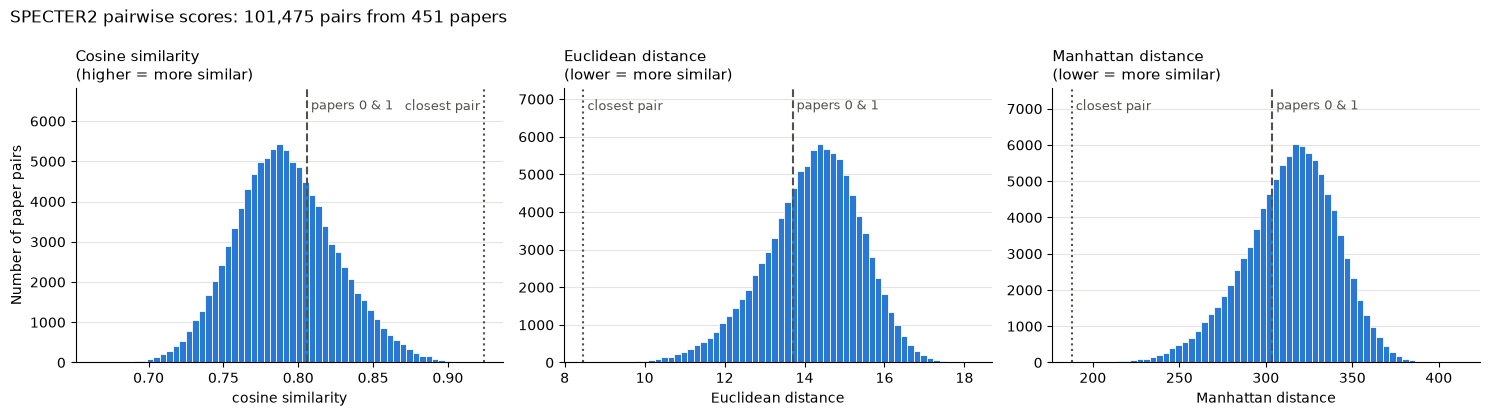

In [15]:
import matplotlib.pyplot as plt

rows, cols = np.triu_indices(len(specter_embeddings), k=1)  # each pair of different papers once

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, matrix) in zip(axes, specter_matrices.items()):
    higher_is_closer = name == "cosine similarity"
    pair_values = matrix[rows, cols]
    closest = pair_values.max() if higher_is_closer else pair_values.min()

    ax.hist(pair_values, bins=60, color="#2a78d6", edgecolor="white", linewidth=0.6)
    top = ax.get_ylim()[1]
    ax.set_ylim(top=top * 1.2)  # headroom so the labels sit above the bars
    for value, label, style in [(matrix[0, 1], "papers 0 & 1", "--"), (closest, "closest pair", ":")]:
        ax.axvline(value, color="#52514e", linestyle=style, linewidth=1.5)
        label_on_left = value == closest and higher_is_closer  # keep the edge label inside the plot
        ax.text(value, top * 1.12, f" {label} ", ha="right" if label_on_left else "left",
                va="center", color="#52514e", fontsize=9)

    direction = "higher = more similar" if higher_is_closer else "lower = more similar"
    ax.set_title(f"{name.capitalize()}\n({direction})", loc="left", fontsize=11)
    ax.set_xlabel(name)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)

    print(f"{name:20s} median {np.median(pair_values):8.3f} | middle 90% of pairs: "
          f"{np.percentile(pair_values, 5):.3f} to {np.percentile(pair_values, 95):.3f}")

axes[0].set_ylabel("Number of paper pairs")
fig.suptitle(f"SPECTER2 pairwise scores: {len(rows):,} pairs from {len(specter_embeddings)} papers", x=0.01, ha="left")
fig.tight_layout()
plt.show()

Cosine similarities all seem to be quite high, meaning that even completely unrelated papers will have a cosine similarity of 0.7+. Maybe this is because all research papers have a similar tone, but I thought this would be less of an issue for an embedding model trained on research papers only. 

### Sanity check: abstracts of the closest pair under each measure

In [16]:
import textwrap

# closest pair of different papers under each measure
closest_pairs = {}
for name, matrix in specter_matrices.items():
    rows, cols = np.triu_indices_from(matrix, k=1)
    pair_values = matrix[rows, cols]
    best = pair_values.argmax() if name == "cosine similarity" else pair_values.argmin()
    closest_pairs.setdefault((rows[best], cols[best]), []).append(f"{name} = {pair_values[best]:.3f}")

# print each distinct pair once, listing every measure that picked it
for (i, j), measures in closest_pairs.items():
    print(f"Closest pair under: {'; '.join(measures)}\n")
    for index in (i, j):
        paper = works_clean.iloc[index]
        print(f"[{index}] {paper['title']}")
        print(f"Source: {paper['source_name']} ({paper['publication_year']}) | {paper['openalex_id']}\n")
        print(textwrap.fill(paper["abstract"], width=110), "\n")

Closest pair under: cosine similarity = 0.924; Euclidean distance = 8.469; Manhattan distance = 187.848

[186] Preface
Source: The Ecumenical Review (2014) | https://openalex.org/W2332010821

All Things New: Faith, Formation and the Future It was my great joy to serve as Dean of the Global Ecumenical
Theological Institute (GETI) in conjunction with the 10th Assembly of the World Council of Churches (WCC).I
left this exciting event with a fresh spirit of hope for the future of the ecumenical movement and am
delighted that the Ecumenical Review has agreed to do this special issue as a way to share some of the fresh
perspectives growing out of this event with the wider Christian family.Our hope and dream in GETI was not only
for an event in Korea (as significant as that was) but rather that this event will plant the seed for "the
future of ecumenism and the transformation of world Christianity in the 21st century" (as we subtitled the
GETI).Publications such as this special edition of The

These have the greatest similarity in all three distance metrics, however semantically they seem unrelated. 186 appears to be a review unrelated to research, while 335 appears to be a film review. This again shows that context ≠ concept, as we learned in class. 

Both of these are not the kind of observations I want in my sample, suggesting that I need better data cleaning first and foremost. The exact similarity metric I choose does not appear to matter as much, but I will check that below by comparing to what extent the 10 nearest neighbors are shared on average between distance metrics. This can be done with Jaccard similarity. 

### Do the measures agree on each paper's 10 nearest neighbors?

In [17]:
from itertools import combinations

k = 10

def nearest_neighbors(matrix, higher_is_closer, k):
    """Indices of each paper's k nearest neighbors, excluding the paper itself."""
    scores = -matrix if higher_is_closer else matrix.copy()  # make "smaller = closer" for every measure
    np.fill_diagonal(scores, np.inf)                         # a paper is not its own neighbor
    return np.argsort(scores, axis=1)[:, :k]

neighbors = {name: nearest_neighbors(matrix, name == "cosine similarity", k)
             for name, matrix in specter_matrices.items()}

for name_a, name_b in combinations(neighbors, 2):
    shared = np.array([len(set(a) & set(b)) for a, b in zip(neighbors[name_a], neighbors[name_b])])
    jaccard = shared / (2 * k - shared)  # |A ∩ B| / |A ∪ B| for two lists of k papers each
    print(f"{name_a} vs {name_b}:")
    print(f"  mean Jaccard {jaccard.mean():.3f} | on average {shared.mean():.1f} of {k} neighbors shared | "
          f"identical lists for {(shared == k).mean():.0%} of papers | lowest Jaccard {jaccard.min():.3f}")

cosine similarity vs Euclidean distance:
  mean Jaccard 0.942 | on average 9.7 of 10 neighbors shared | identical lists for 70% of papers | lowest Jaccard 0.667
cosine similarity vs Manhattan distance:
  mean Jaccard 0.833 | on average 9.0 of 10 neighbors shared | identical lists for 27% of papers | lowest Jaccard 0.429
Euclidean distance vs Manhattan distance:
  mean Jaccard 0.840 | on average 9.1 of 10 neighbors shared | identical lists for 29% of papers | lowest Jaccard 0.538


From the results it seems like they all agree strongly with Jaccard scores of above 0.8 in all comparisons, however Manhattan distance has significantly less identical lists of neighbors.

## How does MiniLM score paper 186 and 335?

In [18]:
from sklearn.metrics.pairwise import cosine_similarity

# Compare a pair of papers under MiniLM and SPECTER2.
# MiniLM embedded `works`; SPECTER2 embedded `works_clean`, so papers are matched by OpenAlex ID.
models = {
    "MiniLM": (embeddings, works["openalex_id"].tolist()),
    "SPECTER2": (specter_embeddings, works_clean["openalex_id"].tolist()),
}

def cosine_and_percentile(vectors, a, b):
    """Cosine of papers a and b, and the share of all pairs with a lower cosine."""
    similarities = cosine_similarity(vectors)
    all_pairs = similarities[np.triu_indices_from(similarities, k=1)]
    return similarities[a, b], (all_pairs < similarities[a, b]).mean()

def compare_pair(id_a, id_b):
    titles = works_clean.set_index("openalex_id")["title"]
    print("Paper A:", titles[id_a])
    print("Paper B:", titles[id_b], "\n")
    print(f"{'':10s}{'paper vs mean':>14s}{'A vs B':>9s}{'percentile':>12s}{'A vs B centered':>17s}{'percentile':>12s}")
    for name, (vectors, ids) in models.items():
        a, b = ids.index(id_a), ids.index(id_b)
        mean_vector = vectors.mean(axis=0, keepdims=True)
        to_mean = cosine_similarity(vectors, mean_vector).mean()  # how strongly all papers point in one shared direction
        raw, raw_pct = cosine_and_percentile(vectors, a, b)
        centered, centered_pct = cosine_and_percentile(vectors - mean_vector, a, b)  # shared direction removed
        print(f"{name:10s}{to_mean:14.3f}{raw:9.3f}{raw_pct:12.1%}{centered:17.3f}{centered_pct:12.1%}")

# the closest pair under all three measures: the "Preface" and the film review
cosine = specter_matrices["cosine similarity"]
rows, cols = np.triu_indices_from(cosine, k=1)
best = cosine[rows, cols].argmax()
compare_pair(works_clean["openalex_id"].iloc[rows[best]], works_clean["openalex_id"].iloc[cols[best]])

Paper A: Preface
Paper B: Ancient galaxy found to be surprisingly dusty 

           paper vs mean   A vs B  percentile  A vs B centered  percentile
MiniLM             0.158    0.046       66.4%            0.033       71.3%
SPECTER2           0.890    0.924      100.0%            0.318       98.6%


Looks like MiniLM did a better job of distinguishing these two papers.

In [19]:
# a pair MiniLM rates as very similar: its closest pair among papers that are in both tables
in_both = works["openalex_id"].isin(works_clean["openalex_id"]).to_numpy()
minilm_similarities = cosine_similarity(embeddings)
rows, cols = np.triu_indices_from(minilm_similarities, k=1)
candidates = in_both[rows] & in_both[cols]
best = np.argmax(np.where(candidates, minilm_similarities[rows, cols], -np.inf))
id_a, id_b = works["openalex_id"].iloc[rows[best]], works["openalex_id"].iloc[cols[best]]

abstracts = works_clean.set_index("openalex_id")["abstract"]
for label, paper_id in (("A", id_a), ("B", id_b)):
    print(f"Abstract {label}: {abstracts[paper_id][:300]}...\n")
compare_pair(id_a, id_b)

Abstract A: Communication skills are key to every area of healthcare. Effective communication is what enables us to establish the patient’s agenda, i.e. perception, concerns, needs and expectations, adequately convey a sense of care and compassion, tailor information appropriately, negotiate involvement in deci...

Abstract B: OBJECTIVES: Learning effective communication is essential for physicians. Effective communication has been shown to affect healthcare outcomes, including patient safety, adherence rates, patient satisfaction, and enhanced teamwork. The importance of these skills has become even more apparent in rece...

Paper A: Compassionate and effective communication: key skills and principles
Paper B: Developing a Communication Curriculum and Workshop for an Internal Medicine Residency Program 

           paper vs mean   A vs B  percentile  A vs B centered  percentile
MiniLM             0.158    0.660      100.0%            0.643      100.0%
SPECTER2           0.890    0.899

### Notes on MiniLM vs SPECTER2

MiniLM seems to perform better? Its most similar pair makes a lot more sense than SPECTER2's most similar pair however that is only one example. I may have to manually check the top 20 pairs of each embedding model to conclude which one is better.

`paper vs mean` shows the average cosine similarity between all papers and the mean vector. For SPECTER2 that similarity is very high, indicating that all vectors point in the same direction as the average while in MiniLM the embeddings point in all different directions. This explains the high scores from SPECTER2 and why unrelated papers have a high cosine similarity. When subtracting the mean vector (`A vs B centered`), the results between MiniLM and SPECTER2 look more similar (MiniLM doesnt change much since the effect of the average vector was not very big). 

## Summary of my process, results, and next steps

I tested the methods on a random sample of English-language OpenAlex articles from 2013–2016 across all fields, not yet on the field I will study.

**Choosing a representation.** In a separate exploratory notebook, count vectors and TF-IDF found largely the same nearest neighbors, while dense embeddings found quite different ones. I chose dense embeddings because they capture meaning beyond shared words.

**What didn't work, and how I revised it.**
1. *Token limit.* MiniLM silently truncates long text, which cut off the end of many abstracts (usually the results and conclusions). I switched to SPECTER2, which is trained on scientific papers, accepts longer inputs, and expects the title plus the abstract. Truncation also varied by year, which could bias year-by-year comparisons.
2. *Software setup.* SPECTER2's "proximity" adapter required extra libraries, pinned package versions, and a kernel restart.
3. *Data quality.* Reading the abstracts revealed placeholders, author lists, and non-English text despite the English filter. I added a stricter filter and stripped "Abstract" labels and copyright lines, at the cost of a few genuine short abstracts.

**Testing the similarity measures.**
- *Agreement.* Cosine, Euclidean, and Manhattan mostly agree on each paper's nearest neighbors; Manhattan differs the most.
- *Sanity check.* All three picked the same closest pair: a church-journal preface and a film review filed under an unrelated astronomy title. Neither is research; both are informal, first-person prose, which shows that context ≠ concept.
- *Shared direction and centering.* SPECTER2 gives even unrelated papers high cosine similarity because all of its vectors lean in the same direction. Subtracting the mean vector removes that lean. It changes cosine rankings but not Euclidean distances, so knowledge extent is unaffected. After centering, the preface and film review are no longer the top pair, but they remain each other's nearest neighbor.
- *MiniLM vs SPECTER2.* MiniLM was not fooled by the preface and film review, and its most similar pair (two papers on communication skills in healthcare) makes clear sense; SPECTER2 also ranks that pair near the top, but it places several non-research items close together.

**What I learned.** At first I concluded that the distance measure matters much less than data cleaning. That still holds, but the shared direction in SPECTER2's vectors and the choice of embedding model mattered more than I expected. I am now unsure which model to use: SPECTER2 handles full abstracts and is built for science but groups non-research text together, while MiniLM separated the junk pair better but truncates many abstracts. Euclidean distance remains the natural choice for knowledge extent, but because that measure depends on the single most extreme paper in each sample, cleaning comes first.

**Next steps.**
- Exclude non-research items with OpenAlex's `is_paratext` filter and title rules (e.g. "Preface", "Editorial").
- Choose the embedding model by manually inspecting each model's top 20 pairs and running the validation below.
- For cosine-based neighbor analyses, decide between raw and centered vectors, using one fixed reference mean so that years stay comparable.
- Validate against outside measures, as both readings did: Gentzkow and Shapiro (2010) used congressional ideology scores and readers' ratings, and Hoberg and Phillips (2016) used managers' views of their competitors and firms' responses to economic shocks. I could:
  - *Citations:* test whether papers that cite each other are closer than random pairs (following Motohashi et al.).
  - *Human raters:* show people one paper and two others, ask which is more similar to the first, and check agreement with the embeddings, paralleling the readings' use of readers and managers. Raters should not see the model's scores, and several raters per comparison would show how consistently people agree.
- Select my field, embed larger samples, and later measure interdisciplinarity from the field composition of each paper's nearest neighbors (following Motohashi et al.).

## Reflection on social implications

My project asks how the semantic breadth of a field changes as its publication volume grows. This week showed that a measure of "breadth" is only as meaningful as the decisions about what counts as a scientific paper and which instrument measures it.

First, the dataset is a social product. OpenAlex labeled prefaces, news items, and a film review as "articles" and labeled Japanese, Russian, and Portuguese abstracts as English, and more than a third of papers had no abstract, often because of publisher policies. Filtering to clean English abstracts means I will measure the breadth of *English-language science with available abstracts*, not science as a whole. If these coverage gaps change over time, part of any trend could reflect who is visible in the database rather than what researchers study, so I should report coverage alongside my results.

Second, the closest-pair result illustrates the "context ≠ concept" idea from week 2 and lab 2: SPECTER2 paired a preface with a film review because both are informal, first-person prose, not because they share a topic. If scientific writing becomes more standardized over time, breadth could appear to shrink because styles converge, even if ideas do not. Gentzkow and Shapiro (2010) ran into a similar problem: some phrases passed their chi-square filter because of idiosyncratic speech, such as one Republican's 22 references to the "Grand Ole Opry," rather than political slant. In both cases a strong statistical signal reflects something other than the construct being measured.

Third, the embedding model is not a neutral instrument. SPECTER2 was trained on scientific papers which is perhaps why it seems to place texts that are not papers close together. In contrast, MiniLM, a general-purpose model, did not, at least for the preface and film review. The model therefore carries its own boundary between science and non-science. Chu and Evans (2021) found that attention concentrates on established work as fields grow. Choosing a model is a theoretical decision about what "similar" means.

This connects to our class discussion about ground truth: OpenAlex topics are classifier outputs with about 82% accuracy, and embedding distances reflect training data, which is why outside validation such as human raters matters. Kozlowski and Evans show that embeddings can track cultural change (such as the meaning of social class) over time, but only with a fixed measuring instrument, so I will use one model and one cleaning procedure for every year. This week moved me closer to answering my research question by showing that the main threats to validity are the definition of the corpus and the choice of model, not the choice of distance measure.